# EDA корпуса технических инструкций

Годовой проект: анализ корпуса для поиска ответов по тексту, таблицам и схемам.

[Чеклист](https://docs.google.com/document/d/1eHSE9a3qsbgTl_w8lufTnGSJUmajbBfG4FGfDq1cbIg/edit)
· [85 PDF в Drive](https://drive.google.com/drive/folders/1rfNnKmHLSG3mkVbMDcy040v4phgAtNbp).

**Единица наблюдения — физическая страница PDF; нумерация начинается с 1.**
Номер, напечатанный в самой инструкции, может отличаться. Документы имеют разную длину;
доля страниц и доля документов отвечают на разные вопросы.

Этот ноутбук читает результаты воспроизводимого локального извлечения и проверяет SHA-256
исходных файлов. Если результатов ещё нет, он запускает извлечение. Для полного пересчёта
установите `REBUILD=True`. Случайная выборка страниц использует seed=42.
Автоматические признаки называются кандидатами: наличие картинки не доказывает необходимость VLM.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from yearproj.eda import question_analysis, run, sha256_file

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "Откройте ноутбук из папки проекта"
OUT = ROOT / "reports/eda"
REBUILD = False  # True: повторить локальное извлечение всех PDF; OCR и API не используются
print("Python:", sys.executable)
print("Корень проекта:", ROOT)


Python: C:\prog\maga\yearproj\.venv\Scripts\python.exe
Корень проекта: C:\prog\maga\yearproj


In [2]:
if REBUILD or not (OUT / "summary.json").exists():
    summary = run(ROOT, refresh=REBUILD)
else:
    summary = json.loads((OUT / "summary.json").read_text(encoding="utf-8"))

actual_files = {p.name: sha256_file(p) for p in (ROOT / "data/raw/drive_manuals").glob("*.pdf")}
assert actual_files == summary["file_hashes"], "Корпус изменился: установите REBUILD=True"
assert sha256_file(ROOT / "data/meta/drive_corpus.json") == summary["manifest_hash"]
assert sha256_file(ROOT / "data/meta/benchmark_qa.csv") == summary["qa_hash"], "QA изменились: нужен пересчёт"
pages = pd.read_csv(OUT / "pages.csv", keep_default_na=False)
documents = pd.read_csv(OUT / "documents.csv", keep_default_na=False)
assert pages.page_id.is_unique
assert len(pages) == int(documents.page_count.sum()) == summary["page_count"]
assert pages.image_coverage.between(0, 1 + 1e-9).all()
assert pages.groupby("doc_id").page_num.apply(lambda s: sorted(s) == list(range(1, len(s) + 1))).all()
display(pd.Series({k: summary[k] for k in ["expected_documents", "found_documents", "document_count", "page_count", "coverage_status"]}).to_frame("Значение"))
display(pd.DataFrame(summary["errors"]))
display(pd.Series(summary["versions"], name="Версия"))

,Значение
expected_documents,85
found_documents,85
document_count,85
page_count,5022
coverage_status,complete


""


pymupdf          2.1
pandas         3.1.1
langdetect     1.0.9
matplotlib    3.11.2
Name: Версия, dtype: str

### Проверка качества источников

В `MAN-19` вместо руководства обнаружена рекламная веб-страница; файл помечен для исключения
перед бенчмарком. Решение связано с SHA-256 конкретного файла. Сводные доли ниже описывают
исходные 85 PDF, включая этот источник. Остальные документы не объявляются прошедшими
сплошную ручную проверку.

In [3]:
review = pd.read_csv(ROOT / "data/meta/document_review.csv", keep_default_na=False)
assert sha256_file(ROOT / "data/meta/document_review.csv") == summary["document_review"]["review_file_hash"]
display(review[["doc_id", "decision", "reason", "evidence_pages"]])

,doc_id,decision,reason,evidence_pages
0,MAN-19_De'Longhi_Magnifica_S_(ECAM_22.110),exclude,Вместо инструкции рекламная веб-страница с пре...,1;2


## 1. Состав корпуса и страниц

В `documents.csv` — одна строка на PDF, в `pages.csv` — на страницу.
Размеры страницы измеряются в PDF points (1 point = 1/72 дюйма).
Площадь изображений — площадь объединения их размещений, делённая на площадь страницы;
перекрывающиеся изображения не учитываются дважды. Порог значимой растровой графики — 1%.
Векторная графика учитывается отдельно; 20 векторных элементов — лишь эвристический порог.
Таблицы ищутся по геометрии линий без ML-моделей, поэтому таблицы без рамок могут быть пропущены.

Взаимоисключающие категории используют приоритет: кандидат в сканы → нет текста, прочее →
кандидат с таблицей → графика → текст без обнаруженной графики. Для точного числа картинок,
таблиц и схем нужна ручная разметка с независимыми полями, поскольку эти элементы пересекаются.

,page_count,size_bytes,total_chars,total_tokens
count,85.0,85.0,85.0,85.0
mean,59.1,6730837.9,310825.9,14200.2
std,65.8,9181059.6,1059937.0,13100.4
min,2.0,23564.0,0.0,0.0
25%,25.0,1521993.0,68417.0,5358.0
50%,38.0,3116607.0,130623.0,10863.0
75%,62.0,9173962.0,243821.0,17410.0
max,456.0,50496928.0,9726224.0,55627.0


,Страниц,"Доля, %"
page_type_candidate,,
graphics_candidate,3143,62.58
table_candidate,1023,20.37
text_without_detected_graphics,654,13.02
no_text_other,134,2.67
scan_candidate,68,1.35


,Страниц
table_detection_status,
ok,4066
skipped_complex_page,714
no_vector_paths,242


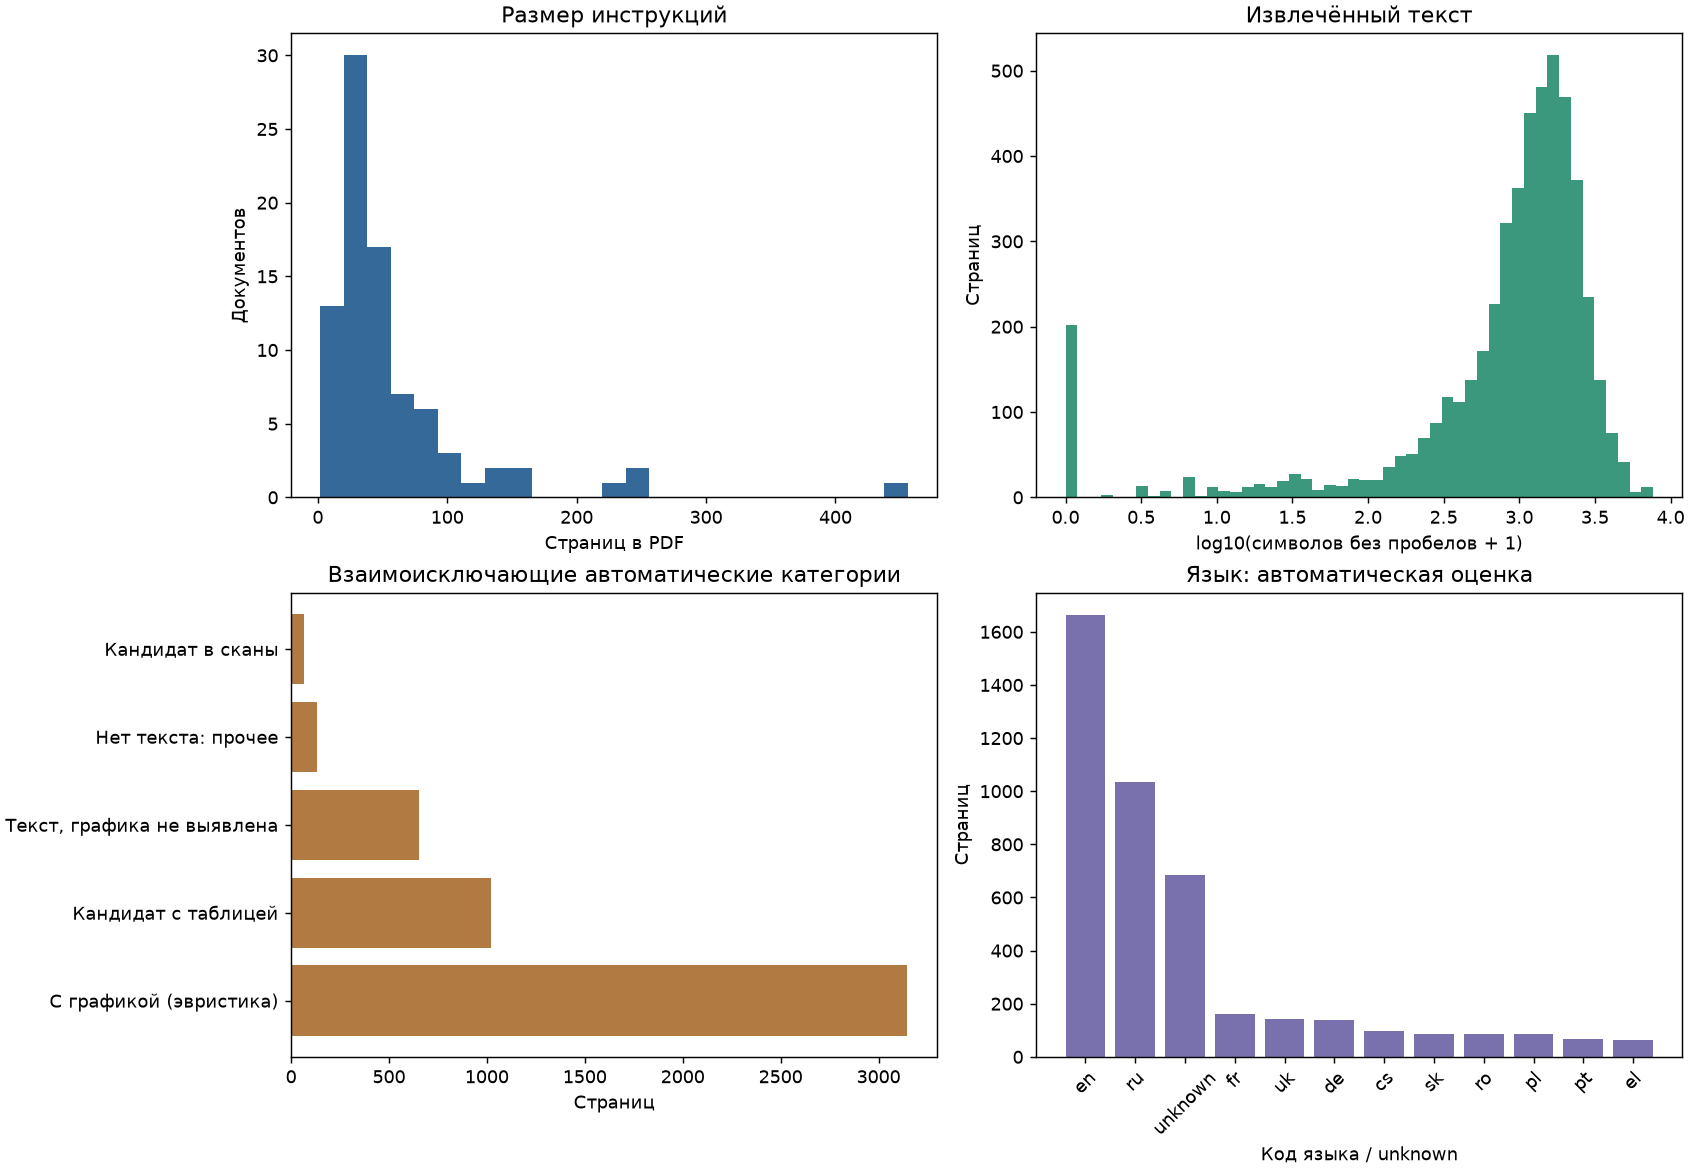

In [4]:
display(documents[["page_count", "size_bytes", "total_chars", "total_tokens"]].describe().round(1))
types = pages.page_type_candidate.value_counts().rename("Страниц").to_frame()
types["Доля, %"] = (100 * types["Страниц"] / len(pages)).round(2)
display(types)
display(pages.table_detection_status.value_counts().rename("Страниц").to_frame())
display(Image(filename=str(OUT / "overview.png"), width=1100))

## 2. Нет текстового слоя, сканы и качество извлечения

Отсутствие извлекаемого текста — наблюдаемый признак. Кандидат в скан дополнительно требует
растрового покрытия ≥80%. Пустые страницы и иллюстрации без текста не обязательно являются сканами.
`sparse_text`: менее 100 извлечённых символов; этот признак может означать обложку, схему,
фото или плохое извлечение. Скан с OCR-слоем может иметь много текста — OCR здесь не проверен.

На некоторых арабских страницах `sort=True` добавляет сотни тысяч пробелов выравнивания.
Это артефакт извлечения, поэтому `char_count` нельзя напрямую сравнивать с объёмом содержания.
Используйте `nonspace_char_count` и `whitespace_share`; график показывает
`log10(nonspace_char_count + 1)` без удаления выбросов.

,Страниц,"Доля, %"
Нет извлекаемого текста,202,4.02
Кандидаты в сканы,68,1.35
Менее 100 символов,351,6.99


,doc_id,page_num,char_count,image_coverage,page_type_candidate
53,MAN-10_Worcester_Bosch_Greenstar_12Ri_-_24Ri,54,0,1.000000,scan_candidate
2148,MAN-54_Panasonic_SD-RD250,4,0,1.000000,scan_candidate
2147,MAN-54_Panasonic_SD-RD250,3,0,1.000000,scan_candidate
2318,MAN-58_Bosch-BIC7101B1_instr,22,0,0.000000,no_text_other
2370,MAN-5_Baxi_AVS_75_Interface_Module,10,0,0.000000,no_text_other
2295,MAN-57_Bosch-BIC510NB0_instr,23,0,0.000000,no_text_other
2146,MAN-54_Panasonic_SD-RD250,2,0,1.000000,scan_candidate
4187,MAN-81_Ballu_BIH-L-2.0,1,0,0.065832,no_text_other
4186,MAN-80_Ballu_BPAC-09_CP_N1_24Y,20,0,0.000000,no_text_other
2145,MAN-54_Panasonic_SD-RD250,1,0,1.000000,scan_candidate


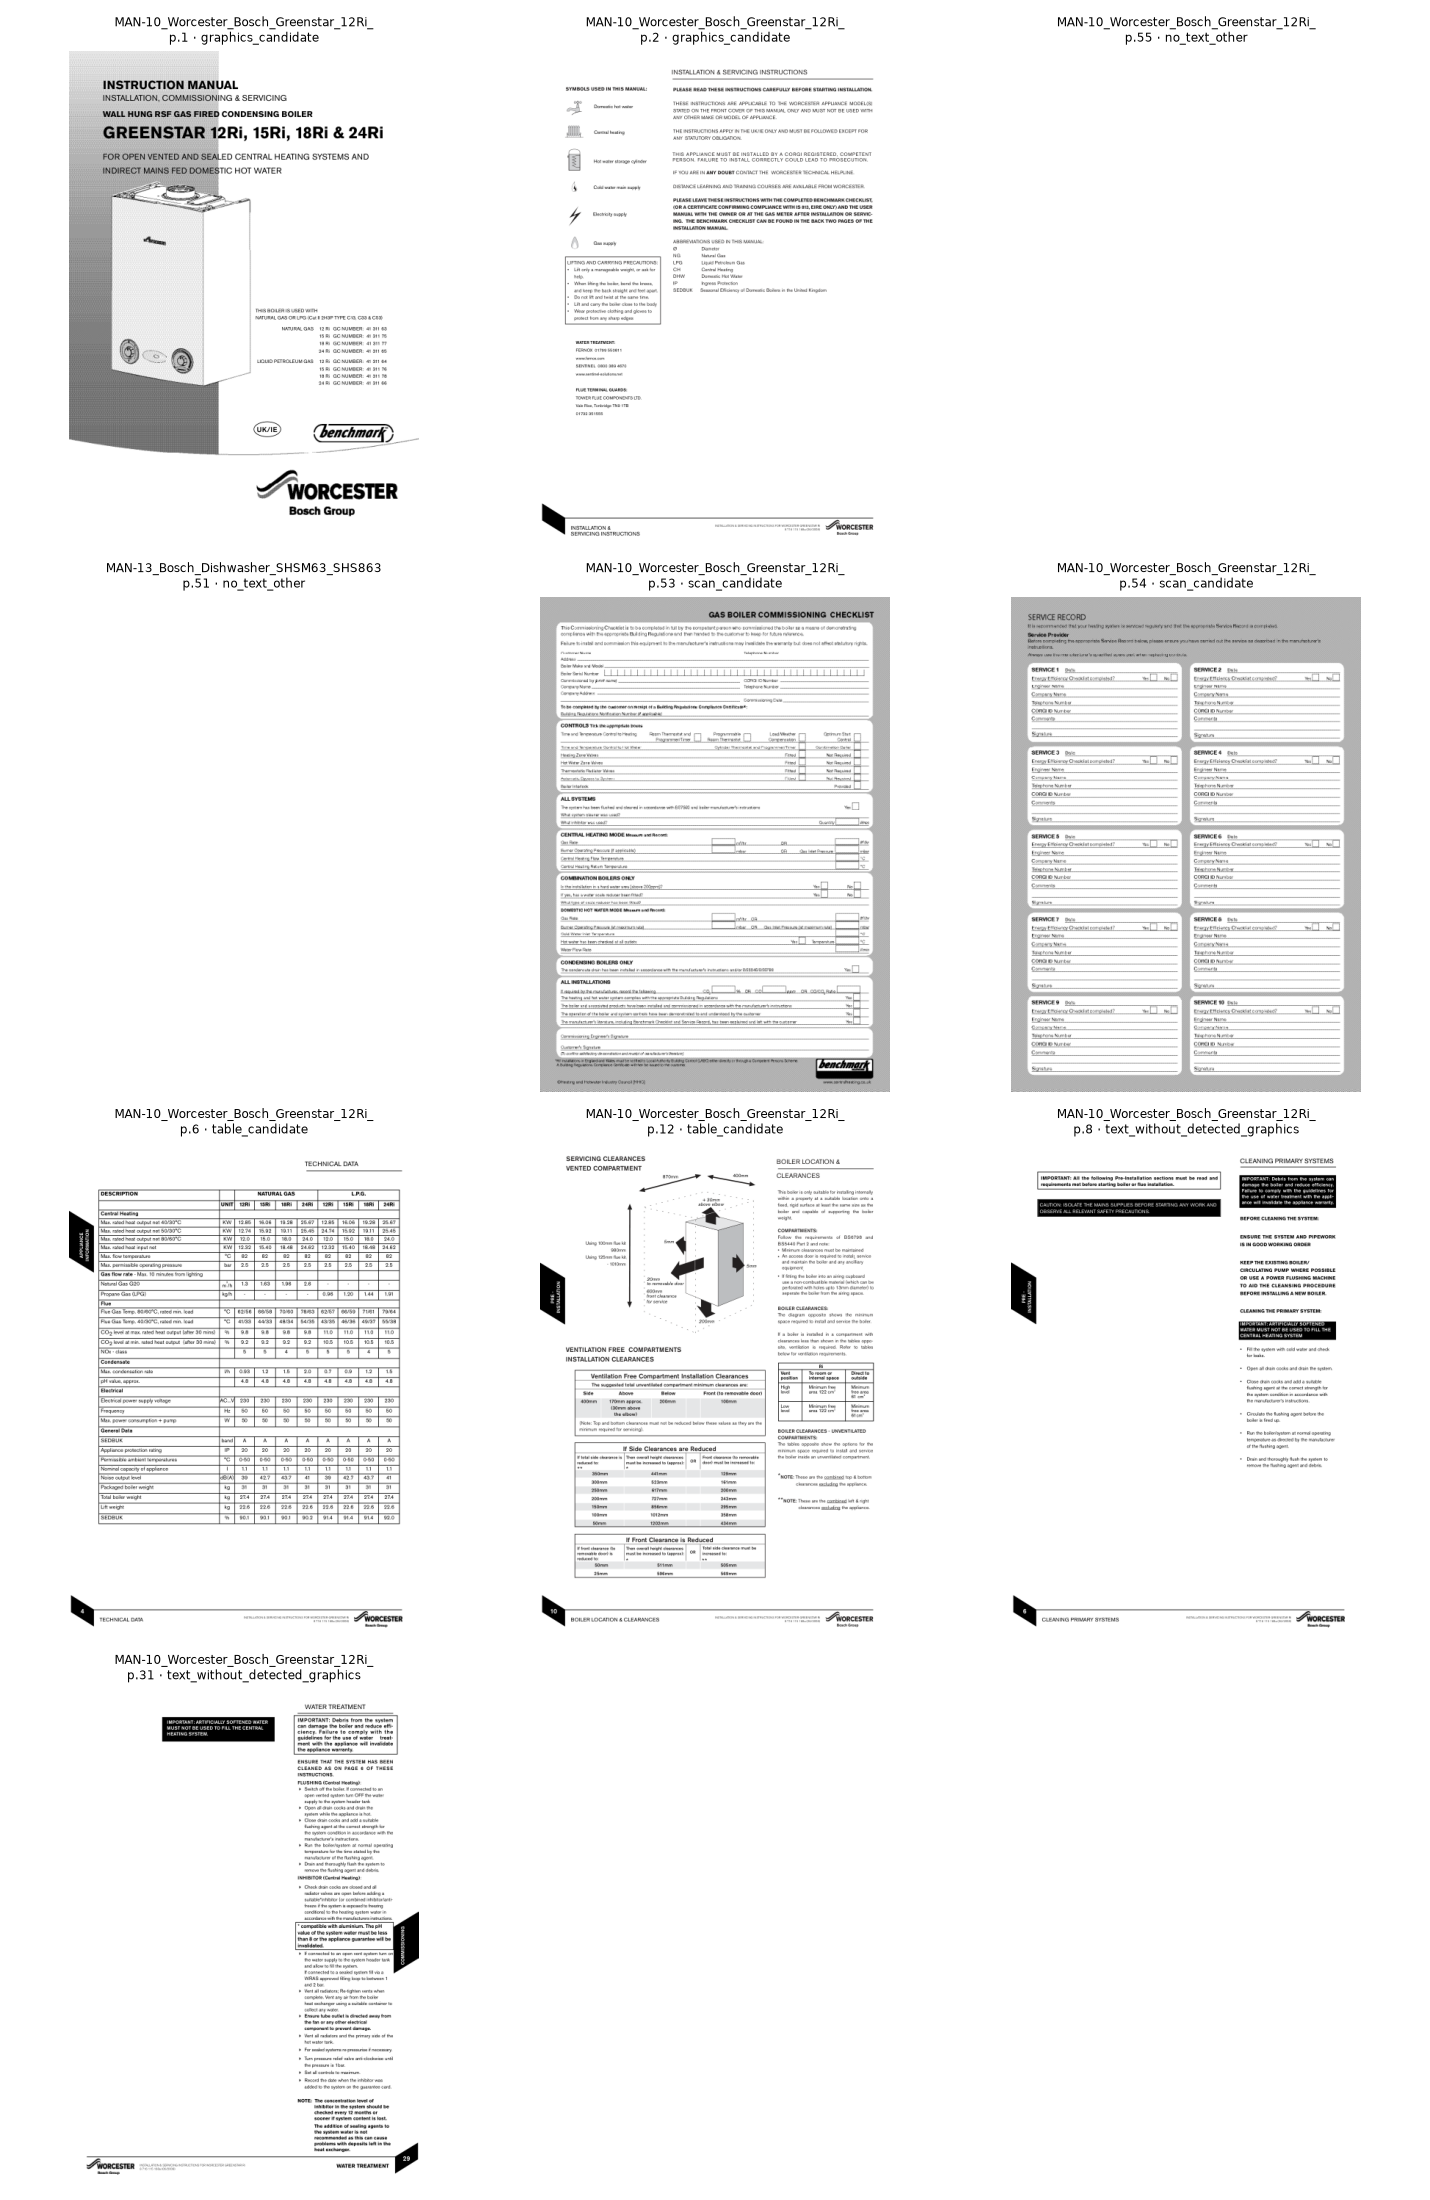

,Качество извлечения
whitespace_90pct_pages,141
maximum_raw_chars,1028415
maximum_nonspace_chars,7653
note,"Raw char_count includes PDF alignment spaces, ..."


,doc_id,page_num,char_count,nonspace_char_count,whitespace_share
1904,MAN-45_Bosch_MSM6M_ErgoMaster,92,1028415,1730,0.998318
1809,MAN-44_Bosch_MSM6B_MSMP,17,717750,1739,0.997577
1903,MAN-45_Bosch_MSM6M_ErgoMaster,91,678678,2168,0.996806
1869,MAN-45_Bosch_MSM6M_ErgoMaster,57,527202,2293,0.995651
1874,MAN-45_Bosch_MSM6M_ErgoMaster,62,513085,2304,0.995510
1894,MAN-45_Bosch_MSM6M_ErgoMaster,82,457047,2057,0.995499
2264,MAN-56_Bosch_TAT3P42,8,418675,2224,0.994688
1810,MAN-44_Bosch_MSM6B_MSMP,18,408138,1190,0.997084
1902,MAN-45_Bosch_MSM6M_ErgoMaster,90,407960,1636,0.995990
1842,MAN-45_Bosch_MSM6M_ErgoMaster,30,387101,2478,0.993599


In [5]:
quality = pd.Series({
    "Нет извлекаемого текста": int(pages.no_text_layer.sum()),
    "Кандидаты в сканы": int(pages.scan_candidate.sum()),
    "Менее 100 символов": int(pages.sparse_text.sum()),
}, name="Страниц").to_frame()
quality["Доля, %"] = (quality["Страниц"] / len(pages) * 100).round(2)
display(quality)
display(pages.sort_values("char_count").head(15)[["doc_id", "page_num", "char_count", "image_coverage", "page_type_candidate"]])
display(Image(filename=str(OUT / "contact_sheet.png"), width=1100))
display(pd.Series(summary["text_quality"]).to_frame("Качество извлечения"))
display(pages.nlargest(10, "char_count")[["doc_id", "page_num", "char_count", "nonspace_char_count", "whitespace_share"]])
assert pages.nonspace_char_count.le(pages.char_count).all()
assert pages.no_text_layer.eq(pages.char_count.eq(0)).all()


## 3. Языки и русские разделы

`langdetect` применяется к страницам с ≥100 буквами; при оценке <0.8 или недостаточном тексте
ставится `unknown`. Эти оценки не являются калиброванными вероятностями правильного языка.
Кириллица также встречается в украинском, болгарском и других языках, поэтому её доля не заменяет
определение русского языка. Смешение кириллицы и латиницы — повод проверить страницу вручную.

Непрерывные диапазоны `ru` — кандидаты для проверки. На смешанных страницах и общих схемах
нельзя автоматически удалять всё содержимое за пределами русских страниц.

In [6]:
display(pages.language_candidate.value_counts().rename("Страниц").to_frame())
ranges = pd.read_csv(OUT / "russian_ranges.csv")
display(ranges)
display(pages.groupby("doc_id").agg(
    pages=("page_id", "size"), ru_candidates=("russian_candidate", "sum"),
    mixed_script_candidates=("mixed_script_candidate", "sum"),
).sort_values("ru_candidates", ascending=False).head(20))

,Страниц
language_candidate,
en,1664
ru,1036
unknown,686
fr,161
uk,144
de,140
cs,98
sk,87
ro,86


,doc_id,start_page,end_page
0,MAN-22_REDMOND_RMC-M25_RMC-M252_RMC-M253,1,1
1,MAN-22_REDMOND_RMC-M25_RMC-M252_RMC-M253,3,3
2,MAN-22_REDMOND_RMC-M25_RMC-M252_RMC-M253,5,19
3,MAN-22_REDMOND_RMC-M25_RMC-M252_RMC-M253,23,23
4,MAN-22_REDMOND_RMC-M25_RMC-M252_RMC-M253,27,27
...,...,...,...
82,MAN-78_Haier_Coral_HSU-09HPL303,77,77
83,MAN-78_Haier_Coral_HSU-09HPL303,85,85
84,MAN-78_Haier_Coral_HSU-09HPL303,92,92
85,MAN-83_Boneco_U350,384,399


,pages,ru_candidates,mixed_script_candidates
doc_id,,,
MAN-65_kofemashina-delonghi-ecam630-75-tsm,105,103,38
MAN-64_kofemashina-delonghi-ecam470-85-mb,105,102,44
MAN-68_kofemashina-delonghi-exam420-55-gr,62,60,18
MAN-29_Electrolux_EW9F1R61B,60,56,7
MAN-63_kofemashina-delonghi-ecam310-60-gb,57,55,7
MAN-78_Haier_Coral_HSU-09HPL303,92,53,21
MAN-69_kofemashina-delonghi-ecam450-55-g-ex-4,152,43,46
MAN-26_REDMOND_RMC-M4525,44,42,2
MAN-28_Electrolux_EW6S4R26W,44,39,3


## 4. Дубликаты и утечка между выборками

Проверяются SHA-256 файлов, равенство нормализованного текста и Jaccard множеств 5-грамм токенов.
Числа сохраняются; короткие страницы (<100 токенов) не участвуют в поиске повторяющихся страниц.
Порог Jaccard=0.65 — эвристика для проверки, а не подтверждение одинаковых моделей.
Общие разделы безопасности могут повышать сходство. Равенство текста не доказывает равенство графики.

До train/dev/test вручную проверьте семейства моделей и объедините связанные документы.
Случайный split страниц создаёт утечку. Разбиение и обучение в этом ноутбуке не выполняются;
тестовые QA нельзя использовать для настройки поиска или выбора порогов.

In [7]:
duplicate_pairs = pd.read_csv(OUT / "duplicate_pairs.csv")
duplicate_groups = pd.read_csv(OUT / "duplicate_groups.csv", keep_default_na=False)
repeated_pages = pd.read_csv(OUT / "repeated_text_pages.csv")
display(duplicate_pairs)
display(duplicate_groups.groupby("duplicate_group_candidate").size().sort_values(ascending=False).head(15).to_frame("Документов"))
print("Повторяющихся текстовых страниц:", len(repeated_pages))
display(repeated_pages[["doc_id", "page_num", "token_count", "text_sha256"]].head(20))

,doc_a,doc_b,exact_file,exact_text,shingle_jaccard


,Документов
duplicate_group_candidate,
MAN-10_Worcester_Bosch_Greenstar_12Ri_-_24Ri,1
MAN-11_Ideal_Independent_+_Combi_C24-C35,1
MAN-12_Remeha_Avanta_Plus_Combi,1
MAN-13_Bosch_Dishwasher_SHSM63_SHS863,1
MAN-14_Bosch_Dishwasher_Classic_Platform,1
MAN-15_Bosch_Dishwasher_Series_800,1
MAN-16_Samsung_RS2544_RS267_Side-by-Side,1
MAN-17_Samsung_RF28_Sparkling_Water_French_Door,1
MAN-18_Bosch_Built-in_Refrigerator_B36,1


Повторяющихся текстовых страниц: 26


,doc_id,page_num,token_count,text_sha256
0,MAN-37_Panasonic_NN-SN67KS,7,488,7d298ca7c4ec85d18f3fca97f389f8d6e71555ed054f00...
1,MAN-37_Panasonic_NN-SN67KS,8,590,b8225bf3023de5f02631a0e3e61128a4994c539e38ff79...
2,MAN-40_Panasonic_NN-SN77HS-SN97HS,7,488,7d298ca7c4ec85d18f3fca97f389f8d6e71555ed054f00...
3,MAN-40_Panasonic_NN-SN77HS-SN97HS,8,590,b8225bf3023de5f02631a0e3e61128a4994c539e38ff79...
4,MAN-42_Bosch_MCM6_AU,13,579,7a8156a2635cd57089eaf39f6ac05916562c6124958b9c...
5,MAN-42_Bosch_MCM6_AU,14,660,312b72707d1081c0359bc31dac764df036db7cd43d51a8...
6,MAN-42_Bosch_MCM6_AU,15,628,6102ea4f1ddbd08c2a6b9c2833ae8ce7f39aa001795532...
7,MAN-46_Bosch_MSM64120GB,21,579,7a8156a2635cd57089eaf39f6ac05916562c6124958b9c...
8,MAN-46_Bosch_MSM64120GB,22,660,312b72707d1081c0359bc31dac764df036db7cd43d51a8...
9,MAN-46_Bosch_MSM64120GB,23,628,6102ea4f1ddbd08c2a6b9c2833ae8ce7f39aa001795532...


## 5. Распределение вопросов по типам

Исходная разметка: `data/meta/benchmark_qa.csv`. Вопросы не генерируются автоматически и не подменяются
долями страниц. Допустимые типы: `text`, `table`, `schematic`, `mixed`, `unknown`.
Каждый вопрос должен иметь уникальный `q_id`, точный `doc_id`, физическую страницу PDF и ответ.
Выборка должна отражать сценарий использования; принудительный баланс типов меняет оцениваемую долю.

In [8]:
questions, qa = question_analysis(ROOT / "data/meta/benchmark_qa.csv", pages)
assert qa == summary["qa"]
if questions.empty:
    display(Markdown("**Размеченных вопросов пока нет. Распределение типов не определено.** Шаблон и протокол разметки подготовлены."))
else:
    display(questions.question_type.value_counts(dropna=False).rename("Вопросов").to_frame())

**Размеченных вопросов пока нет. Распределение типов не определено.** Шаблон и протокол разметки подготовлены.

## 6. Какая доля ответов требует визуальной информации?

Для каждого вопроса сравните PDF и извлечённый текст целевой страницы (`pages_text.jsonl`).
`requires_visual=yes` — ответ подтверждён PDF, но текст недостаточен; `no` — текста достаточно;
`unknown` — решение ещё не принято. Укажите доказательство в `evidence_notes` и отдельно отметьте,
связана ли проблема с OCR/порядком текста или с пространственным смыслом рисунка.

Пусть $v$ — число `yes`, $n$ — число проверенных (`yes`+`no`), $N$ — всего вопросов.
Тогда $p=v/n$ описывает только проверенную часть. При $n=0$ оценка не определена.
Для всей выборки при неизвестных ответах границы составляют $[v/N,\ (v+N-n)/N]$.
Интервал Wilson 95% рассчитан условно для независимой случайной выборки;
он не устраняет смещение отбора и зависимость вопросов внутри одной инструкции.

In [9]:
if not qa["total"]:
    display(Markdown("**Главный вывод о доле мультимодальных вопросов пока получить нельзя:** отсутствует QA-разметка. Автоматический EDA корпуса показывает, что следует проверить, но не измеряет недоступность ответа по тексту."))
else:
    display(pd.Series(qa).to_frame("Значение"))

**Главный вывод о доле мультимодальных вопросов пока получить нельзя:** отсутствует QA-разметка. Автоматический EDA корпуса показывает, что следует проверить, но не измеряет недоступность ответа по тексту.

## Дальнейшая проверка и итог

`page_review_queue.csv` содержит по одной случайной странице каждого документа и дополнение по редким
автоматическим категориям. Это очередь качественной проверки, не репрезентативная выборка для долей.
Результаты ручной разметки сохраните отдельной копией: очередь пересоздаётся при полном пересчёте.
Для точного количества страниц нужно разметить весь корпус; для оценки доли — заранее зафиксировать
случайный план отбора и учитывать его при расчёте неопределённости.

Следующий шаг — подтвердить русские диапазоны и семейства моделей, затем разметить QA и пересчитать
пункты 5–6. Графики и таблицы корпуса уже рассчитаны. Полный текстовый отчёт доступен ниже.

In [10]:
display(Markdown((OUT / "report.md").read_text(encoding="utf-8")))

# EDA корпуса технических инструкций

Источник: https://drive.google.com/drive/folders/1rfNnKmHLSG3mkVbMDcy040v4phgAtNbp

Чеклист: https://docs.google.com/document/d/1eHSE9a3qsbgTl_w8lufTnGSJUmajbBfG4FGfDq1cbIg/edit

## Охват

- PDF в снимке Drive: 85.
- PDF найдены локально: 85.
- Успешно прочитаны: 85; ошибки: 0.
- Страниц в прочитанных документах: 5022. Пропущенные/повреждённые PDF не входят в знаменатель.
- Проверка охвата: complete.

### Ручная проверка качества источников

- `MAN-19_De'Longhi_Magnifica_S_(ECAM_22.110)`: exclude. Вместо инструкции рекламная веб-страница с предложением открыть обзор; вторая страница содержит только метки image. Нужна замена настоящим руководством. Страницы: 1;2.

Решения записаны в `data/meta/document_review.csv` с SHA-256 проверенного файла.
Рекомендуется исключить документов: 1;
их страниц: 2. Статистика ниже описывает **исходные 85 PDF**,
включая отклонённые источники; остальные документы не объявляются проверенными.
Исходники сохранены. Перед построением бенчмарка замените отклонённые документы настоящими инструкциями.

## 1. Страницы, таблицы, картинки и схемы

Категории ниже — автоматические кандидаты, с приоритетом скан → нет текста → таблица → графика → текст.
Они взаимоисключающие; исходные признаки в `pages.csv` могут пересекаться.

- `graphics_candidate`: 3143 / 5022 (62.6%).
- `table_candidate`: 1023 / 5022 (20.4%).
- `text_without_detected_graphics`: 654 / 5022 (13.0%).
- `no_text_other`: 134 / 5022 (2.7%).
- `scan_candidate`: 68 / 5022 (1.4%).

Таблицы найдены геометрическим алгоритмом по линиям: 1023 / 5022 (20.4%).
Ошибок детектора: 0; слишком сложных страниц пропущено: 714.
Таблицы без рамок и таблицы в сканах могут быть пропущены. Векторные линии включают рамки,
логотипы и украшения: это не классификатор электрических схем.
Точное число страниц с картинками, таблицами, схемами и только текстом требует ручной разметки.
Очередь `page_review_queue.csv` содержит по одной случайной странице каждого PDF и редкие категории;
её нельзя использовать для несмещённой оценки долей по всему корпусу.

## 2. Текстовый слой и сканы

- Нет извлекаемого текста: 202 / 5022 (4.0%).
- Кандидат в скан (нет текста, объединённая площадь растров ≥80%): 68 / 5022 (1.4%).
- Мало текста (<100 символов): 351 / 5022 (7.0%).

Пустая страница, иллюстрация и скан могут иметь одинаковые признаки. OCR не запускался.
Скан с OCR-слоем попадёт в страницы с текстом; качество OCR автоматически не измерено.
Символы извлечены в порядке `sort=True`; это не гарантирует правильный порядок колонок.

### Артефакты пробелов

В текстовом слое некоторых страниц, в частности арабских, `sort=True` добавляет большое
число пробелов выравнивания. Максимальная исходная длина: 1028415
символов; страниц с ≥90% пробельных символов: 141.
Это артефакт извлечения, а не сопоставимый объём содержания.
`nonspace_char_count` и `whitespace_share` в `pages.csv` отделяют эту проблему;
`text_quality_review.csv` содержит страницы для проверки. Гистограмма показывает
`log10(nonspace_char_count + 1)` и сохраняет все страницы, включая пустые.
Исходный текст сохранён; токенизация для дубликатов схлопывает пробелы.

## 3. Языки и русские разделы

Языки-кандидаты: {"en": 1664, "ru": 1036, "unknown": 686, "fr": 161, "uk": 144, "de": 140, "cs": 98, "sk": 87, "ro": 86, "pl": 85, "pt": 66, "el": 65, "es": 64, "sv": 62, "ar": 62, "he": 60, "fi": 50, "it": 49, "lt": 36, "ko": 34, "nl": 33, "et": 25, "zh-cn": 25, "bg": 23, "no": 22, "tr": 20, "da": 19, "hr": 18, "sl": 18, "hu": 17, "lv": 17, "id": 13, "th": 13, "ja": 13, "ca": 6, "fa": 2, "vi": 2, "so": 1}.
Страниц с кандидатом `ru`: 1036.
`russian_ranges.csv` содержит непрерывные диапазоны страниц-кандидатов, нумерация PDF с 1.
Это очередь проверки, не готовые границы обрезки. Текстовые подсказки и вероятности `langdetect`
не калиброваны; обложки и страницы с несколькими языками требуют проверки.
Для общих схем и смешанных страниц нужен выбор блоков; удалять их целиком нельзя.
Автоматическое вырезание русского корпуса не выполнялось.

## 4. Дубликаты и разделение данных

- Пар совпадающих файлов SHA-256: 0.
- Пар с равным нормализованным текстом документа: 0.
- Всего пар-кандидатов (включая близкий текст): 0.
- Повторяющихся страниц с ≥100 токенами: 26.

Для близких документов используется Jaccard множеств 5-грамм токенов ≥0.65.
Это эвристика: общая техника безопасности может повысить сходство, сканы без текста не сравниваются.
Равный текст страниц не доказывает совпадение картинок. Проверяйте `duplicate_pairs.csv` и
`duplicate_groups.csv`; дополните группы семействами моделей вручную. Разделять страницы случайно
нельзя: все вопросы и страницы семейства/дубликата должны принадлежать одной части train/dev/test.
Общий корпус поиска может быть доступен всем запросам, но тестовые QA нельзя использовать
для выбора порогов, промптов, чанкинга или параметров ретривера. Разделение пока не выполнялось.

## 5–6. Вопросы и обоснование мультимодальности

Размеченных вопросов нет. Распределение типов и доля ответов, недоступных по тексту, **не определены**. Заполните `data/meta/benchmark_qa.csv` по инструкции в README.

`requires_visual=yes` означает: ответ подтверждён PDF, но извлечённого текста страницы
недостаточно для этого ответа (например, важны стрелки, взаимное расположение или обозначения).
Табличный вопрос может быть доступен по тексту; наличие изображения само по себе не означает `yes`.
Отдельно различайте недостаток извлечения текста/OCR и необходимость пространственного анализа.
Главный вывод о мультимодальности появится после сравнения ответов по PDF и текстовому слою
на заранее выбранной и описанной выборке. Метрики retrieval и accuracy здесь не вычислялись.

## Воспроизводимость

Параметры, SHA-256 файлов и версии зависимостей записаны в `summary.json` и `documents.csv`.
Seed: 42. Все вычисления локальные; обучения, OCR, API и VLM нет.
Обзорные графики: `overview.png`; примеры исходных страниц: `contact_sheet.png`.
